#Управление роботом М20П и построение траекторий

Таблица Денавита-Хартенберга для манипулятора М20П

| Звено | <font size="3">$\theta_i$ | <font size="3">$d_i$ | <font size="3">$a_i$ | <font size="3">$\alpha_i$ |
| :---: | :---: | :---: | :---: | :---: |
| 1 | <font size="3">$q_1$ | <font size="3">$d_0 + d_1$ | <font size="3">$0$ | <font size="3">$0^\circ$ |
| 2 | <font size="3">$0$   | <font size="3">$d_2$ | <font size="3">$a_2$ | <font size="3">$90^\circ$ |
| 3 | <font size="3">$0$   | <font size="3">$d_3$ | <font size="3">$0$ | <font size="3">$0^\circ$ |
| 4 | <font size="3">$q_4$ | <font size="3">$0$ | <font size="3">$0$ | <font size="3">$-90^\circ$ |
| 5 | <font size="3">$q_5$ | <font size="3">$0$ | <font size="3">$0$ | <font size="3">$90^\circ$ |
| 6 | <font size="3">$q_6$ | <font size="3">$d_G$ | <font size="3">$0$ | <font size="3">$0^\circ$ |

### Определение параметров манипулятора

| <font size="4">Параметр | <font size="4">Описание |
| :--- | :--- |
| <font size="4">$d_0, d_1$ | <font size="4">Константы, составляющие высоту основания манипулятора |
| <font size="4">$a_2$ | <font size="4">Константа, составляющая вынос плеча |
| <font size="4">$d_G$ | <font size="4">Константа, составляющая длину инструмента |
| <font size="4">$q_1$ | <font size="4">Угол поворота основания |
| <font size="4">$d_2$ | <font size="4">Выдвижение первого линейного привода |
| <font size="4">$d_3$ | <font size="4">Выдвижение второго линейного привода |
| <font size="4">$q_4, q_5, q_6$ | <font size="4">Параметры вращения кисти |

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import display, Math

from matplotlib.animation import FuncAnimation

In [ ]:
# "Библиотека" для различных операций для манипуляторов
class RMath:

    # Матрица вращения вокруг оси X
    @staticmethod
    def rx(theta):
        c, s = np.cos(theta), np.sin(theta)
        return np.array([[1, 0,  0, 0],
                         [0, c, -s, 0],
                         [0, s,  c, 0],
                         [0, 0,  0, 1]])

    # Матрица вращения вокруг оси Y
    @staticmethod
    def ry(theta):
        c, s = np.cos(theta), np.sin(theta)
        return np.array([[ c, 0, s, 0],
                         [ 0, 1, 0, 0],
                         [-s, 0, c, 0],
                         [ 0, 0, 0, 1]])

    # Матрица вращения вокруг оси Z
    @staticmethod
    def rz(theta):
        c, s = np.cos(theta), np.sin(theta)
        return np.array([[c, -s, 0, 0],
                         [s,  c, 0, 0],
                         [0,  0, 1, 0],
                         [0,  0, 0, 1]])

    # Матрица переноса
    @staticmethod
    def tran(x, y, z):
        T = np.eye(4)
        T[:3, 3] = [x, y, z]
        return T

    # Матрица Денавита-Хартенберга
    @staticmethod
    def dh_matrix(theta, d, a, alpha):
        return RMath.rz(theta) @ RMath.tran(0, 0, d) @ RMath.tran(a, 0, 0) @ RMath.rx(alpha)

    # Функция для извлечения углов из матрицы поворота
    @staticmethod
    def extract_zyz(R):
        if np.abs(R[2, 2]) < 1.0 - 1e-10:
            q5 = np.arccos(R[2, 2])
            q4 = np.arctan2(R[1, 2], R[0, 2])
            q6 = np.arctan2(R[2, 1], -R[2, 0])
        else:
            q5 = 0.0 if R[2, 2] > 0 else np.pi
            q4 = np.arctan2(R[1, 0], R[0, 0])
            q6 = 0.0
        return np.array([q4, q5, q6])

    @staticmethod
    def generate_ik_input(x, y, z, x_rotate=0, y_rotate=0, z_rotate=0):
      x_rotate_rad = np.deg2rad(x_rotate)
      y_rotate_rad = np.deg2rad(y_rotate)
      z_rotate_rad = np.deg2rad(z_rotate)

      R = RMath.rx(x_rotate_rad) @ RMath.ry(y_rotate_rad) @ RMath.rz(z_rotate_rad)

      T_target = np.eye(4)
      T_target[:3, :3] = R[:3, :3]
      T_target[:3, 3] = [x, y, z]

      return T_target

    # Функция для вывода Якобияна и некоторой информации о нем в консоль
    @staticmethod
    def print_jacobian(J):
        rows = []
        for row in J:
            rows.append(" & ".join(f"{v:.3f}" for v in row))
        matrix_latex = " \\\\ ".join(rows)

        display(Math(r"J = \begin{bmatrix}" + matrix_latex + r"\end{bmatrix}"))

        rank = np.linalg.matrix_rank(J, tol=1e-6)
        det = np.linalg.det(J)

        display(Math(r"\text{rank}(J) = " + str(rank)))
        display(Math(r"\det(J) = " + f"{det:.6f}"))

        if rank < 6:
            display(Math(r"\text{Сингулярность}"))
        else:
            display(Math(r"\text{Сингулярность отсутствует}"))

In [ ]:
# Класс робота М20П
class M20P:
    def __init__(self, d0=0.1, d1=0.1, a2=0.5, d_G = 0.3):
        self.d0 = d0 # Высота основания 0
        self.d1 = d1 # Высота основания 1
        self.a2 = a2 # Смещение плеча
        self.d_G = d_G # Длина инструмента

    # Прямая кинематика. Вычисление положения инструмента
    def forward_kinematics(self, q):
        T01 = RMath.dh_matrix(q[0], self.d0 + self.d1, 0, 0)
        T12 = RMath.dh_matrix(0, q[1], self.a2, np.pi/2)
        T23 = RMath.dh_matrix(0, q[2], 0, 0)

        R_wrist = RMath.dh_matrix(q[3], 0, 0, -np.pi/2) @ RMath.dh_matrix(q[4], 0, 0, np.pi/2) @ RMath.dh_matrix(q[5], self.d_G, 0, 0);

        T_total = T01 @ T12 @ T23 @ R_wrist
        return T_total

    # Обратная кинематика
    def inverse_kinematics(self, T_target):
        P_tip = T_target[:3, 3]
        R_target = T_target[:3, :3]
        P_wc = P_tip - self.d_G * R_target[:3, 2]

        x, y, z = P_wc
        R_xy = np.sqrt(x**2 + y**2)

        if R_xy < self.a2:
            return None

        q1 = np.arccos(self.a2/R_xy) + np.atan2(y, x)
        d3 = np.sqrt((x-self.a2*np.cos(q1))**2 + (y-self.a2*np.sin(q1))**2)
        d2 = z - self.d0 - self.d1

        T03 = self.forward_kinematics([q1, d2, d3, 0, 0, 0])
        R03 = T03[:3, :3]

        R_wrist = R03.T @ R_target
        q4, q5, q6 = RMath.extract_zyz(R_wrist)

        return [q1, d2, d3, q4, q5, q6]

    # Вычисление якобияна
    def jacobian(self, q):
        T01 = RMath.dh_matrix(q[0], self.d0 + self.d1, 0, 0)
        T12 = RMath.dh_matrix(0, q[1], self.a2, np.pi/2)
        T23 = RMath.dh_matrix(0, q[2], 0, 0)
        T34 = RMath.dh_matrix(q[3], 0, 0, -np.pi/2)
        T45 = RMath.dh_matrix(q[4], 0, 0, np.pi/2)
        T56 = RMath.dh_matrix(q[5], self.d_G, 0, 0)

        T = [np.eye(4), T01, T01@T12, T01@T12@T23,
            T01@T12@T23@T34, T01@T12@T23@T34@T45,
            T01@T12@T23@T34@T45@T56]

        pe = T[6][:3, 3] # Позиция конца инструмента
        J = np.zeros((6, 6))
        joint_types = ['R', 'L', 'L', 'R', 'R', 'R'] # Типы шаринров, где R-вращательный, L-линейный
        for i in range(6):
            z = T[i][:3, 2]
            p = T[i][:3, 3]
            if joint_types[i] == 'R':
                J[:3, i] = np.cross(z, pe - p)
                J[3:, i] = z
            else:
                J[:3, i] = z
                J[3:, i] = np.zeros(3)
        return J

    # Вычисление якобияна численным методом
    def numerical_jacobian(self, q, eps=1e-7):
        J = np.zeros((6, 6))

        T0 = self.forward_kinematics(q)
        p0 = T0[:3, 3]
        R0 = T0[:3, :3]

        for i in range(6):
            q_plus = q.copy()
            q_plus[i] += eps

            T_plus = self.forward_kinematics(q_plus)
            p_plus = T_plus[:3, 3]
            R_plus = T_plus[:3, :3]

            J[:3, i] = (p_plus - p0) / eps

            dR = (R_plus - R0) / eps
            S = dR @ R0.T
            J[3, i] = S[2, 1]
            J[4, i] = S[0, 2]
            J[5, i] = S[1, 0]
        return J

    # Симуляция прямой дифференциальной кинематики
    def simulate_forward_differential_kimenatics(self, q0, q_speeds, dt, steps):
        q = np.array(q0, dtype=float)
        q_speeds = np.array(q_speeds, dtype=float)
        q_records = [q.copy()]
        endeffector_pos_records = [self.forward_kinematics(q)[:3, 3].copy()]
        for _ in range(steps):
            q += q_speeds * dt
            q_records.append(q.copy())
            endeffector_pos_records.append(self.forward_kinematics(q)[:3,3].copy())
        return np.array(q_records), np.array(endeffector_pos_records)

    # Симуляция обратной дифференциальной кинематики
    def simulate_inverse_differential_kimenatics(self, q0, x_speeds, dt, steps, inversion_method="pseudoinverse"):
        q = np.array(q0, dtype=float)
        x_speeds = np.array(x_speeds, dtype=float)
        q_records = [q.copy()]
        endeffector_pos_records = [self.forward_kinematics(q)[:3, 3].copy()]

        for _ in range(steps):
            J = self.jacobian(q)
            n = len(q)

            if inversion_method == "pseudoinverse":
                J_inv = np.linalg.pinv(J)
                q_dot = J_inv @ x_speeds
            elif inversion_method == 'nullspace_manipulativity_damping':
                JJt = J @ J.T

                lambda_damping = 1e-3
                J_inv = J.T @ np.linalg.inv(JJt + lambda_damping * lambda_damping * np.eye(J.shape[0]))
                qdot_primary = J_inv @ x_speeds

                def manipulability(q):
                    J = self.jacobian(q)
                    return np.sqrt(max(np.linalg.det(J @ J.T), 0.0))

                def grad_manip(q, eps=1e-6):
                    g = np.zeros_like(q)
                    w0 = manipulability(q)
                    for i in range(len(q)):
                        dq = np.zeros_like(q)
                        dq[i] = eps
                        g[i] = (manipulability(q + dq) - w0) / eps
                    return g
                grad_w = grad_manip(q)
                P = np.eye(len(q)) - J_inv @ J
                k0 = 5.0
                q_dot = qdot_primary + P @ (k0 * grad_w)
            q = q + q_dot * dt
            q_records.append(q.copy())
            endeffector_pos_records.append(self.forward_kinematics(q)[:3,3].copy())
        return np.array(q_records), np.array(endeffector_pos_records)

    # Функция для визуализации манипулятора
    def visualize(self, q):
        T01 = RMath.dh_matrix(q[0], self.d0 + self.d1, 0, 0)
        T12_1 = T01 @ RMath.dh_matrix(0, q[1], 0, 0)
        T12_2 = T12_1 @ RMath.dh_matrix(0, 0, self.a2, np.pi/2)
        T23 = T12_2 @ RMath.dh_matrix(0, q[2], 0, 0)

        T34 = T23 @ RMath.dh_matrix(q[3], 0, 0, -np.pi/2)
        T45 = T34 @ RMath.dh_matrix(q[4], 0, 0, np.pi/2)
        T56 = T45 @ RMath.dh_matrix(q[5], self.d_G, 0, 0)

        p0 = np.array([0, 0, 0])          # Основание
        p1 = T01[:3, 3]                   # Мотор q1
        p2 = T12_1[:3, 3]                 # Линейный привод d2
        p3 = T12_2[:3, 3]                 # Плечо
        p4 = T23[:3, 3]                   # Линейный привод d3
        p_end = T56[:3, 3]                # Инструмент

        origin = p_end
        scale = 0.2
        x_axis = origin + T56[:3, 0] * scale
        y_axis = origin + T56[:3, 1] * scale
        z_axis = origin + T56[:3, 2] * scale

        points = np.array([p0, p1, p2, p3, p4, p_end])
        labels = ['Основание', 'Мотор q1', 'Линейный привод d2', 'Плечо', 'Линейный привод d3', "Инструмент"]

        fig = plt.figure(figsize=(12, 12))
        ax = fig.add_axes([0.2, 0.1, 0.6, 0.8], projection='3d', computed_zorder=False)
        ax.set_box_aspect((1, 1, 1))

        ax.plot(points[:-1,0], points[:-1,1], points[:-1,2], '-o', linewidth=4, markersize=10, color='coral', zorder=5)
        ax.plot(points[-2:, 0], points[-2:, 1], points[-2:, 2], '-o', linewidth=4, markersize=10, color='maroon', zorder=5)

        ax.quiver(origin[0], origin[1], origin[2], T56[0, 0], T56[1, 0], T56[2, 0], length=scale, color='red', linewidth=2, label='Ось X Инструмента', zorder=10)
        ax.quiver(origin[0], origin[1], origin[2], T56[0, 1], T56[1, 1], T56[2, 1], length=scale, color='green', linewidth=2, label='Ось Y Инструмента', zorder=10)
        ax.quiver(origin[0], origin[1], origin[2], T56[0, 2], T56[1, 2], T56[2, 2], length=scale, color='blue', linewidth=2, label='Ось Z Инструмента', zorder=10)

        for i, p in enumerate(points):
            text = f"{labels[i]} ({p[0]:.2f}, {p[1]:.2f}, {p[2]:.2f})"
            ax.text(p[0], p[1], p[2], text, fontsize=8, fontweight='bold', zorder=15, ha='center', va='bottom')

        ax.set_xlabel('X (м)')
        ax.set_ylabel('Y (м)')
        ax.set_zlabel('Z (м)')
        ax.set_title(f"Параметры приводов: [{round(np.rad2deg(q[0]),2)}°, {round(q[1],2)}м, {round(q[2],2)}м, {round(np.rad2deg(q[3]),2)}°, {round(np.rad2deg(q[4]),2)}°, {round(np.rad2deg(q[5]),2)}°]")

        max_range = np.array([points[:,0].max()-points[:,0].min(),
                              points[:,1].max()-points[:,1].min(),
                              points[:,2].max()-points[:,2].min()]).max() / 2.0
        max_range *= 1.3
        mid_x = (points[:,0].max()+points[:,0].min()) * 0.5
        mid_y = (points[:,1].max()+points[:,1].min()) * 0.5
        ax.set_xlim(mid_x - max_range, mid_x + max_range)
        ax.set_ylim(mid_y - max_range, mid_y + max_range)
        ax.set_zlim(0, points[:,2].max() * 1.3)

        ax.plot_trisurf([mid_x-max_range, mid_x+max_range, mid_x-max_range, mid_x+max_range],
                [mid_y-max_range, mid_y-max_range, mid_y+max_range, mid_y+max_range],
                [0, 0, 0, 0], color='white', antialiased=False, zorder=1)

        plt.legend()
        plt.show()

    # Функция для визуализации рабочей области манипулятора
    def plot_workspace(self):
        q1_range = np.linspace(0, 2*np.pi, 100)
        d2_range = np.linspace(0, 1, 10)
        d3_range = np.linspace(0, 2, 20)

        x_points, y_points, z_points = [], [], []

        for q1 in q1_range:
            for d2 in d2_range:
                for d3 in d3_range:
                    T = self.forward_kinematics([q1, d2, d3, 0, 0, 0])
                    x_points.append(T[0,3])
                    y_points.append(T[1,3])
                    z_points.append(T[2,3])

        fig = plt.figure(figsize=(10, 10))
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(x_points, y_points, z_points,c=z_points, s=50, alpha=0.1, cmap='magma')
        ax.set_title("Рабочая область")

        ax.set_zlim(self.d0+self.d1, max(z_points) * 1.3)

        plt.show()

$$
a_{eff}=\frac{dq}{dt^2 \cdot (k_b(k_b-1) + k_b \cdot k_c)}
$$

In [ ]:
class PathPlanner:
    def _trapezoidal_profile(q0, qf, v_max, a_max, T, dt=1/120):
        dq = qf - q0
        dist = abs(dq)

        t_b_max = v_max / a_max
        dist_ramp = v_max * v_max / a_max

        if dist >= dist_ramp:
            t_b = t_b_max
        else:
            t_b = np.sqrt(dist / a_max)

        k_f = int(round(T / dt))
        k_b = int(round(t_b / dt))
        k_c = max(0, k_f - 2 * k_b)

        den = dt**2 * (k_b * (k_b - 1) + k_b * k_c)
        a_eff = dq / den if den != 0 else 0.0

        q = np.zeros(k_f + 1)
        dq_arr = np.zeros(k_f + 1)
        ddq_arr = np.zeros(k_f + 1)
        q[0] = q0

        for k in range(k_f):
            if k < k_b:
                ddq = a_eff
            elif k < k_b + k_c:
                ddq = 0.0
            else:
                ddq = -a_eff

            ddq_arr[k] = ddq
            dq_arr[k+1] = dq_arr[k] + ddq * dt
            q[k+1] = q[k] + dq_arr[k] * dt

        t = np.arange(0, (k_f + 1)) * dt

        return t, q, dq_arr, ddq_arr

    def _min_time_for_joint(dq, v_max, a_max):
        dist = abs(dq)
        dist_ramp = v_max**2 / a_max
        if dist >= dist_ramp:
            return v_max / a_max + dist / v_max
        else:
            return 2 * np.sqrt(dist / a_max)

    def _synchronize_joints(q0, qf, v_max_list, a_max_list):
        times = [PathPlanner._min_time_for_joint(qf[i] - q0[i], v_max_list[i], a_max_list[i]) for i in range(len(q0))]
        T_star = max(times)
        print(f"Минимальные времена по шарнирам: {[round(t, 3) for t in times]}")
        print(f"Синхронизированное время T* = {round(T_star, 3)} с")
        return T_star

    def plan_joints_path(q0, qf, v_max_list, a_max_list, dt):
        T_star = PathPlanner._synchronize_joints(q0, qf, v_max_list, a_max_list)
        trajectories = []
        for i in range(6):
            t, q, dq, ddq = PathPlanner._trapezoidal_profile(q0[i], qf[i], v_max_list[i], a_max_list[i], T_star, dt)
            trajectories.append((t, q, dq, ddq))
        return trajectories

    @staticmethod
    def _polynomial_3_points(q0, q1, q2, t1, t2, dt=1/120):
        A = np.array([
            [t1**3,   t1**4,    t1**5,    t1**6],
            [t2**3,   t2**4,    t2**5,    t2**6],
            [3*t2**2, 4*t2**3,  5*t2**4,  6*t2**5],
            [6*t2,    12*t2**2, 20*t2**3, 30*t2**4]
        ], dtype=float)

        B = np.array([
            q1 - q0,
            q2 - q0,
            0,
            0
        ], dtype=float)

        c = np.linalg.solve(A, B)
        c3, c4, c5, c6 = c

        k_f = int(round(t2 / dt))
        t = np.linspace(0, t2, k_f + 1)

        q = q0 + c3*t**3 + c4*t**4 + c5*t**5 + c6*t**6
        dq = 3*c3*t**2 + 4*c4*t**3 + 5*c5*t**4 + 6*c6*t**5
        ddq = 6*c3*t + 12*c4*t**2 + 20*c5*t**3 + 30*c6*t**4

        return t, q, dq, ddq

    @staticmethod
    def plan_polynomial_joints_path(q0_list, q1_list, q2_list, T_total, dt=1/120):
        trajectories = []

        t1 = T_total / 2.0
        t2 = T_total

        for i in range(6):
            t, q, dq, ddq = PathPlanner._polynomial_3_points(
                q0_list[i], q1_list[i], q2_list[i], t1, t2, dt
            )
            trajectories.append((t, q, dq, ddq))

        return trajectories

    @staticmethod
    def plan_cartesian_path_jacobian(manip, q_start, p_end, T_total, dt=1/120):
        p_start = manip.forward_kinematics(q_start)[:3, 3]
        v_cartesian = np.zeros(6)
        v_cartesian[:3] = (p_end - p_start) / T_total
        steps = int(T_total / dt)

        q_records, _ = manip.simulate_inverse_differential_kimenatics(
            q_start, v_cartesian, dt, steps, inversion_method='nullspace_manipulativity_damping'
        )
        return q_records

    @staticmethod
    def plan_cartesian_path_ik(manip, q_start, p_end, steps_count, T_total, dt=1/120):
        if (steps_count < 2):
            print("[Предупреждение] Количество шагов steps_count должно быть больше 1. Значение автоматически изменено на 2")
            steps_count = 2

        T_start = manip.forward_kinematics(q_start)
        p_start = T_start[:3, 3]
        R_fixed = T_start[:3, :3]

        q_waypoints = []
        for s in range(steps_count):
            p = p_start + (p_end - p_start) * (s / (steps_count - 1))
            T_tgt = np.eye(4)
            T_tgt[:3, :3] = R_fixed
            T_tgt[:3, 3] = p
            q_ik = manip.inverse_kinematics(T_tgt)
            q_waypoints.append(np.array(q_ik) if q_ik is not None else (q_waypoints[-1] if q_waypoints else np.array(q_start)))

        steps_total = int(T_total / dt)
        steps_per_segment = steps_total // (steps_count - 1)
        q_records = []

        for i in range(len(q_waypoints) - 1):
            q_A, q_B = q_waypoints[i], q_waypoints[i+1]
            for s in range(steps_per_segment):
                q_records.append((1 - (s / steps_per_segment)) * q_A + (s / steps_per_segment) * q_B)

        q_records.append(q_waypoints[-1])
        return np.array(q_records)

In [ ]:
manipulator = M20P()

<h1><font color="#DE8393">Задание #1, 2, 3</font></h1>

Минимальные времена по шарнирам: [np.float64(2.778), np.float64(1.5), np.float64(1.5), np.float64(0.591), np.float64(1.023), np.float64(1.182)]
Синхронизированное время T* = 2.778 с


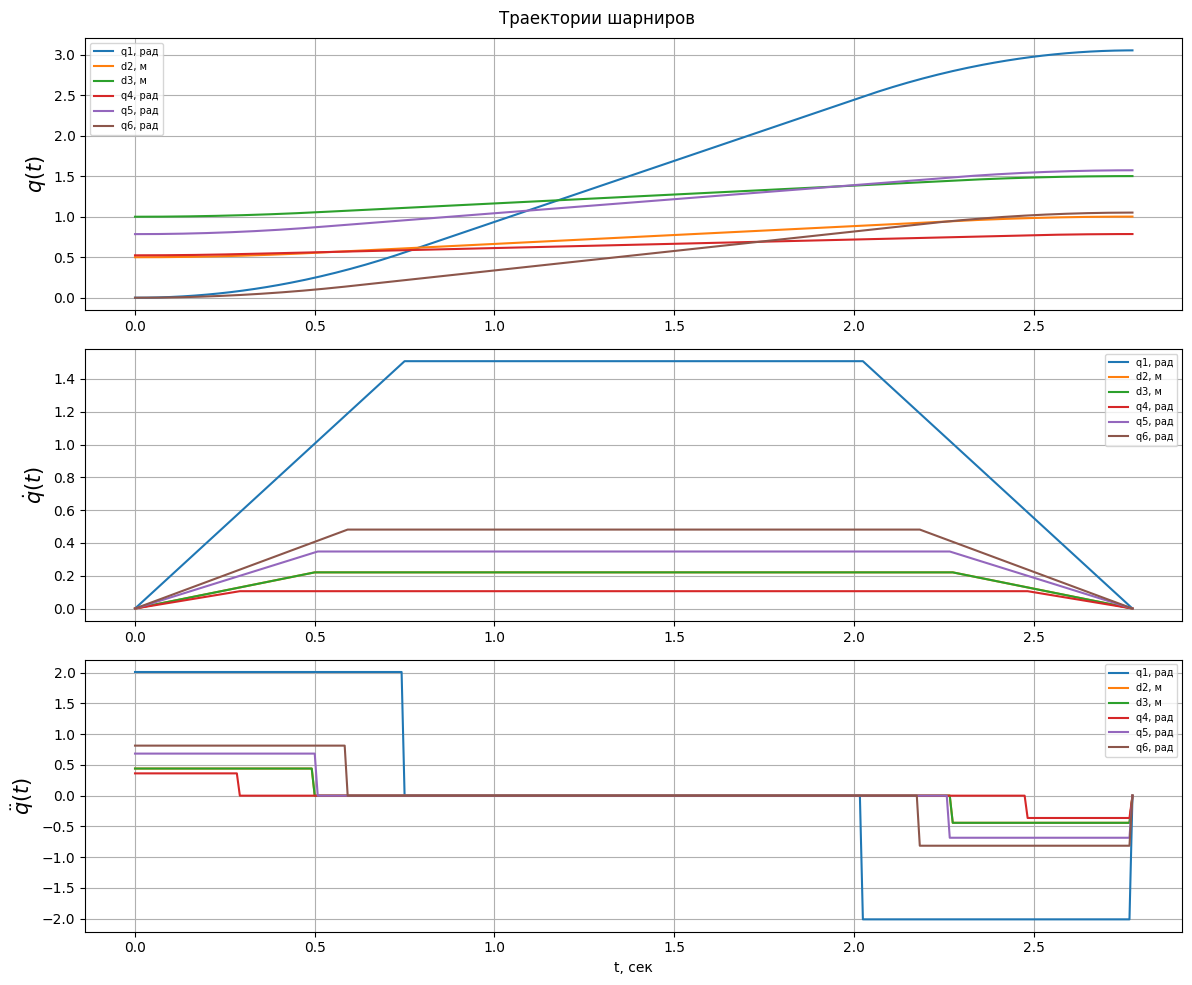

In [ ]:
q0 = np.array([0,     0.5, 1,   np.pi/6,    np.pi/4,  0])
qf = np.array([np.pi-0.1, 1, 1.5, np.pi/4, np.pi/2, np.pi/3])
v_max_list = [1.5, 0.5, 0.5, 2.0, 2.0, 2.0]
a_max_list = [2.0, 1.0, 1.0, 3.0, 3.0, 3.0]
dt = 1 / 120

trapezoidal_trajectories = PathPlanner.plan_joints_path(q0, qf, v_max_list, a_max_list, dt)

joint_names = ['q1, рад', 'd2, м', 'd3, м', 'q4, рад', 'q5, рад', 'q6, рад']
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
fig.suptitle("Траектории шарниров")

for i, (t, q, dq, ddq) in enumerate(trapezoidal_trajectories):
    axes[0].plot(t, q,   label=joint_names[i])
    axes[1].plot(t, dq,  label=joint_names[i])
    axes[2].plot(t, ddq, label=joint_names[i])

axes[0].set_ylabel("$q(t)$", fontsize=15)
axes[1].set_ylabel("$\\dot{q}(t)$", fontsize=15)
axes[2].set_ylabel("$\\ddot{q}(t)$", fontsize=15)
axes[2].set_xlabel("t, сек")
for ax in axes:
    ax.legend(fontsize=7)
    ax.grid(True)

plt.tight_layout()
plt.show()

<h1><font color="#DE8393">Задание #4</font></h1>

Для нахождения реальной траектории я использовал аналитическую формулу из лекции. Затем сравнил с дискретной

$$q(t) = \begin{cases} q_0 + \frac{1}{2} \ddot{q}_{max}^{num} \cdot t^2, & 0 < t \leq t_b^{num} \\ q_0 - \frac{1}{2} \ddot{q}_{max}^{num} \cdot (t_b^{num})^2 + \dot{q}_{max}^{num} \cdot (t - t_b^{num}), & t_b^{num} < t \leq t_f^{num} - t_b^{num} \\ q_f - \frac{1}{2} \ddot{q}_{max}^{num} \cdot (t - t_f^{num})^2, & t_f^{num} - t_b^{num} < t \leq t_f^{num} \end{cases}$$

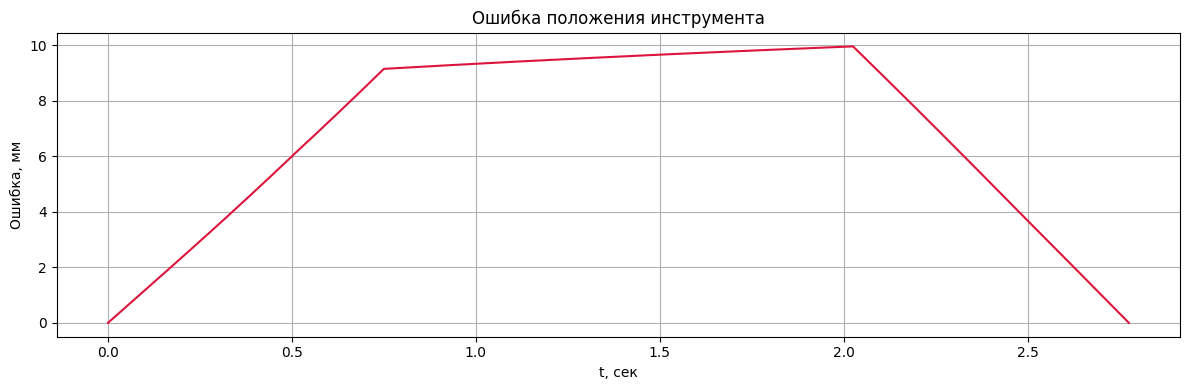

Накопленная ошибка: 19.3282 мм·c
Максимальная ошибка: 9.9526 мм


In [ ]:
def _trapezoidal_profile_continuous(q0, qf, v_max, a_max, T, dt=1/120):
    dq = qf - q0
    dist = abs(dq)

    t_b_max = v_max / a_max
    dist_ramp = v_max * v_max / a_max

    if dist >= dist_ramp:
        t_b = t_b_max
    else:
        t_b = np.sqrt(dist / a_max)

    k_f = int(round(T / dt))
    k_b = int(round(t_b / dt))
    k_c = max(0, k_f - 2 * k_b)

    den = dt**2 * (k_b * (k_b - 1) + k_b * k_c)
    a_eff = dq / den if den != 0 else 0.0

    t_b = k_b * dt
    t_c = k_c * dt
    v_b = a_eff * t_b
    q_b = q0 + 0.5 * a_eff * t_b**2

    t = np.arange(0, (k_f + 1)) * dt
    q = np.zeros(k_f + 1)
    dq_arr = np.zeros(k_f + 1)
    ddq_arr = np.zeros(k_f + 1)

    for k in range(k_f + 1):
        tk = t[k]
        if tk < t_b:
            q[k] = q0 + 0.5 * a_eff * tk**2
            dq_arr[k] = a_eff * tk
            ddq_arr[k] = a_eff
        elif tk < t_b + t_c:
            q[k] = q_b + v_b * (tk - t_b)
            dq_arr[k] = v_b
            ddq_arr[k] = 0.0
        else:
            tau = tk - (t_b + t_c)
            q[k] = q_b + v_b * t_c + v_b * tau - 0.5 * a_eff * tau**2
            dq_arr[k] = v_b - a_eff * tau
            ddq_arr[k] = -a_eff

    return t, q, dq_arr, ddq_arr

T_star = trapezoidal_trajectories[0][0][-1]
continuous_trajectories = [_trapezoidal_profile_continuous(q0[i], qf[i], v_max_list[i], a_max_list[i], T_star, dt) for i in range(6)]

t_axis = trapezoidal_trajectories[0][0]
errors = []
for k in range(len(t_axis)):
    q_disc = np.array([trapezoidal_trajectories[i][1][k] for i in range(6)])
    q_cont = np.array([continuous_trajectories[i][1][k] for i in range(6)])
    p_disc = manipulator.forward_kinematics(q_disc)[:3, 3]
    p_cont = manipulator.forward_kinematics(q_cont)[:3, 3]
    errors.append(np.linalg.norm(p_disc - p_cont))

errors = np.array(errors)

plt.figure(figsize=(12, 4))
plt.plot(t_axis, errors * 1000, color='crimson')
plt.xlabel('t, сек')
plt.ylabel('Ошибка, мм')
plt.title('Ошибка положения инструмента')
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Накопленная ошибка: {errors.sum()*dt*1000:.4f} мм·c")
print(f"Максимальная ошибка: {errors.max()*1000:.4f} мм")

<h1><font color="#DE8393">Задание #5</font></h1>

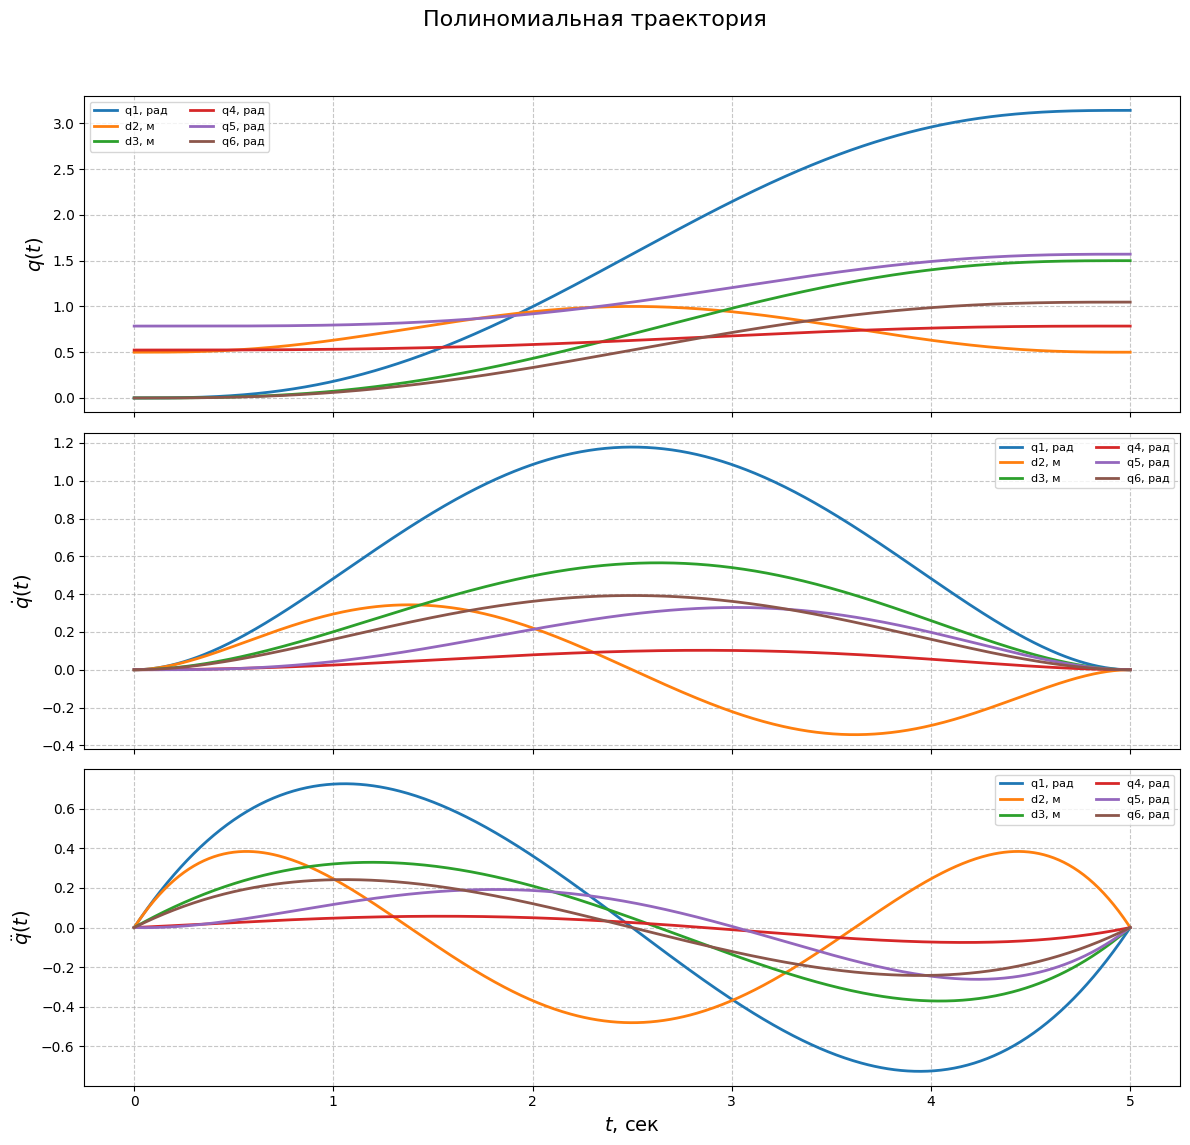

In [ ]:
q0 = np.array([0,     0.5, 0,   np.pi/6, np.pi/4, 0])
q1 = np.array([np.pi/2, 1, 0.7, np.pi/5, np.pi/3, np.pi/6])
q2 = np.array([np.pi, 0.5, 1.5, np.pi/4, np.pi/2, np.pi/3])

dt = 1 / 120
T_total = 5.0

poly_trajectories = PathPlanner.plan_polynomial_joints_path(q0, q1, q2, T_total, dt)

joint_names = ['q1, рад', 'd2, м', 'd3, м', 'q4, рад', 'q5, рад', 'q6, рад']
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
fig.suptitle("Полиномиальная траектория", fontsize=16)

for i, (t, q, dq, ddq) in enumerate(poly_trajectories):
    axes[0].plot(t, q,   label=joint_names[i], linewidth=2)
    axes[1].plot(t, dq,  label=joint_names[i], linewidth=2)
    axes[2].plot(t, ddq, label=joint_names[i], linewidth=2)

axes[0].set_ylabel("$q(t)$", fontsize=14)
axes[1].set_ylabel("$\\dot{q}(t)$", fontsize=14)
axes[2].set_ylabel("$\\ddot{q}(t)$", fontsize=14)
axes[2].set_xlabel("$t$, сек", fontsize=14)

for ax in axes:
    ax.legend(fontsize=8, ncol=2)
    ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

<h1><font color="#DE8393">Задание #6</font></h1>

<h3><font color="#E7FF99">Для построения прямолинейной траектории можно использовать уже готовый метод манипулятора для обратной дифференциальной кинематики.</font></h3>

<p>Для этого нужно лишь рассчитать необходимые скорости чтобы эндеффектор прошёл между двумя позициями за требуемое время. При этом скорости угловых координат зададим в 0, чтобы инструмент не крутился, а смотрел в фиксированную сторону</p>

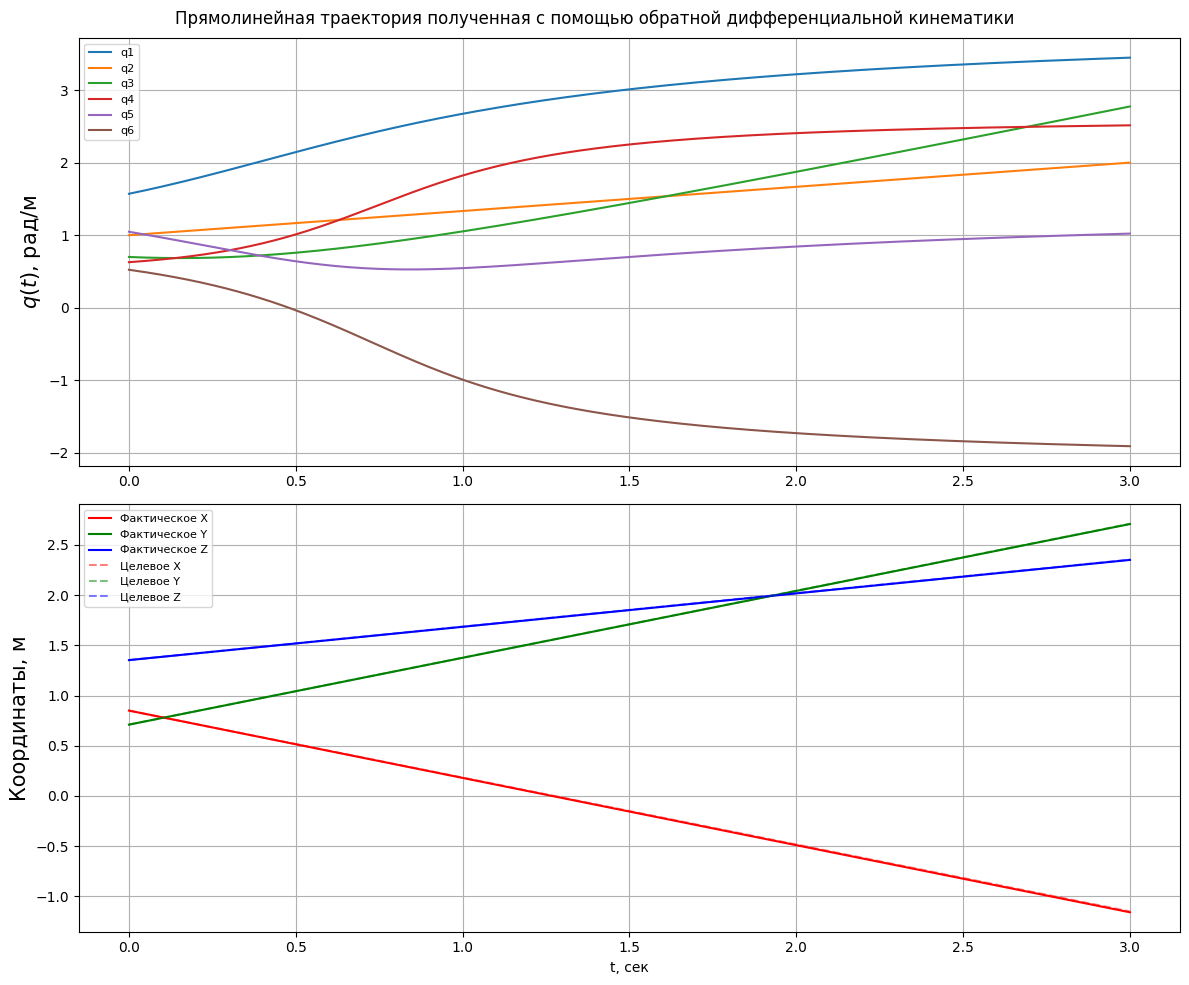

In [ ]:
q_start = np.array([np.pi/2, 1, 0.7, np.pi/5, np.pi/3, np.pi/6])
p_start = manipulator.forward_kinematics(q_start)[:3, 3]
p_end = p_start + np.array([-2, 2, 1])
T_total = 3.0
dt = 1/120

q_records_jac = PathPlanner.plan_cartesian_path_jacobian(manipulator, q_start, p_end, T_total, dt)

p_actual_jac = np.array([manipulator.forward_kinematics(q)[:3, 3] for q in q_records_jac])
t_jac = np.linspace(0, T_total, len(q_records_jac))

fig, axes = plt.subplots(2, 1, figsize=(12, 10))
fig.suptitle("Прямолинейная траектория полученная с помощью обратной дифференциальной кинематики")

for i in range(q_records_jac.shape[1]):
    axes[0].plot(t_jac, q_records_jac[:, i], label=f'q{i+1}')
axes[0].set_ylabel("$q(t)$, рад/м", fontsize=15)

axes[1].plot(t_jac, p_actual_jac[:, 0], 'r', label='Фактическое X')
axes[1].plot(t_jac, p_actual_jac[:, 1], 'g', label='Фактическое Y')
axes[1].plot(t_jac, p_actual_jac[:, 2], 'b', label='Фактическое Z')
axes[1].plot([0, T_total], [p_start[0], p_end[0]], 'r--', alpha=0.5, label='Целевое X')
axes[1].plot([0, T_total], [p_start[1], p_end[1]], 'g--', alpha=0.5, label='Целевое Y')
axes[1].plot([0, T_total], [p_start[2], p_end[2]], 'b--', alpha=0.5, label='Целевое Z')
axes[1].set_ylabel("Координаты, м", fontsize=15)
axes[1].set_xlabel("t, сек")

for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(True)

plt.tight_layout()
plt.show()

<h3><font color="#E7FF99">Теперь посторим графики для прямолинейной траектории полученной с помощью обратной кинематики.</font></h3>

<p>Возьмём два примера: в первом будет 3 промежуточные точки, во втором — 15 промежуточных точек.</p>

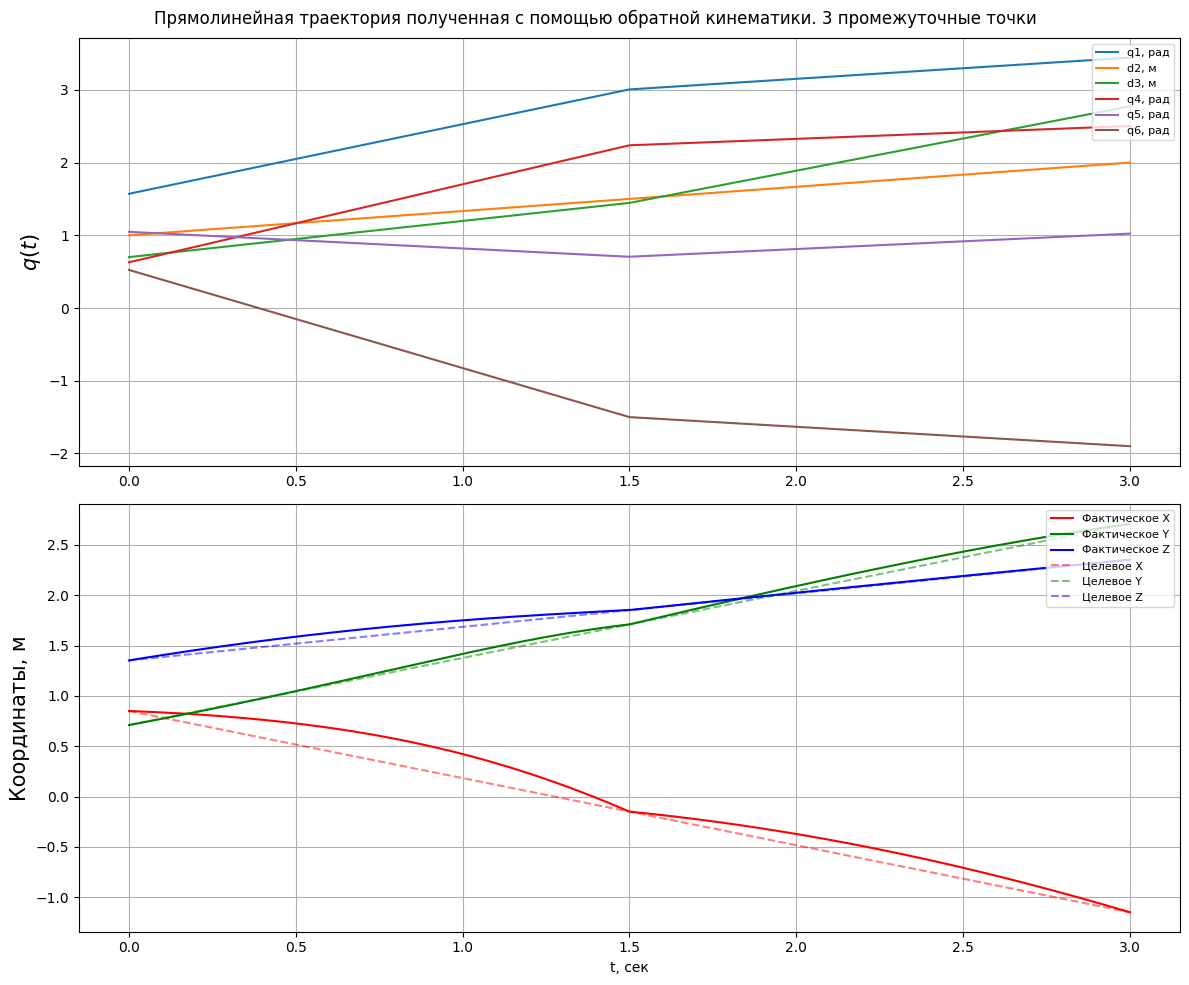

In [ ]:
steps_count = 3
q_records_ik = PathPlanner.plan_cartesian_path_ik(manipulator, q_start, p_end, steps_count, T_total, dt)

p_actual_ik = np.array([manipulator.forward_kinematics(q)[:3, 3] for q in q_records_ik])
t_ik = np.linspace(0, T_total, len(q_records_ik))

fig, axes = plt.subplots(2, 1, figsize=(12, 10))
fig.suptitle(f"Прямолинейная траектория полученная с помощью обратной кинематики. {steps_count} промежуточные точки")

for i in range(q_records_ik.shape[1]):
    axes[0].plot(t_ik, q_records_ik[:, i], label=joint_names[i])
axes[0].set_ylabel("$q(t)$", fontsize=15)

axes[1].plot(t_ik, p_actual_ik[:, 0], 'r', label='Фактическое X')
axes[1].plot(t_ik, p_actual_ik[:, 1], 'g', label='Фактическое Y')
axes[1].plot(t_ik, p_actual_ik[:, 2], 'b', label='Фактическое Z')
axes[1].plot([0, T_total], [p_start[0], p_end[0]], 'r--', alpha=0.5, label='Целевое X')
axes[1].plot([0, T_total], [p_start[1], p_end[1]], 'g--', alpha=0.5, label='Целевое Y')
axes[1].plot([0, T_total], [p_start[2], p_end[2]], 'b--', alpha=0.5, label='Целевое Z')
axes[1].set_ylabel("Координаты, м", fontsize=15)
axes[1].set_xlabel("t, сек")

for ax in axes:
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True)

plt.tight_layout()
plt.show()

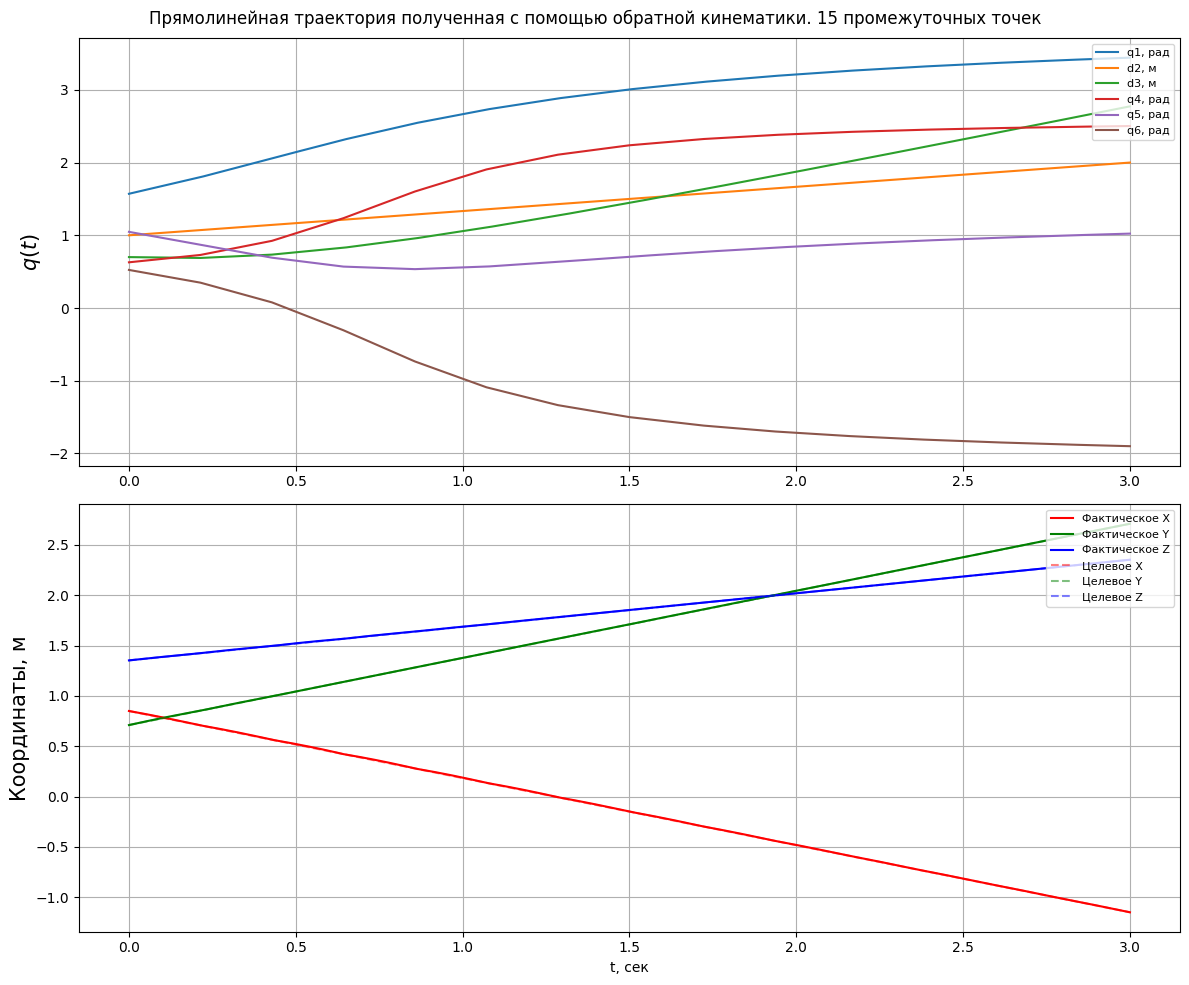

In [ ]:
steps_count = 15
q_records_ik = PathPlanner.plan_cartesian_path_ik(manipulator, q_start, p_end, steps_count, T_total, dt)

p_actual_ik = np.array([manipulator.forward_kinematics(q)[:3, 3] for q in q_records_ik])
t_ik = np.linspace(0, T_total, len(q_records_ik))

fig, axes = plt.subplots(2, 1, figsize=(12, 10))
fig.suptitle(f"Прямолинейная траектория полученная с помощью обратной кинематики. {steps_count} промежуточных точек")

for i in range(q_records_ik.shape[1]):
    axes[0].plot(t_ik, q_records_ik[:, i], label=joint_names[i])
axes[0].set_ylabel("$q(t)$", fontsize=15)

axes[1].plot(t_ik, p_actual_ik[:, 0], 'r', label='Фактическое X')
axes[1].plot(t_ik, p_actual_ik[:, 1], 'g', label='Фактическое Y')
axes[1].plot(t_ik, p_actual_ik[:, 2], 'b', label='Фактическое Z')
axes[1].plot([0, T_total], [p_start[0], p_end[0]], 'r--', alpha=0.5, label='Целевое X')
axes[1].plot([0, T_total], [p_start[1], p_end[1]], 'g--', alpha=0.5, label='Целевое Y')
axes[1].plot([0, T_total], [p_start[2], p_end[2]], 'b--', alpha=0.5, label='Целевое Z')
axes[1].set_ylabel("Координаты, м", fontsize=15)
axes[1].set_xlabel("t, сек")

for ax in axes:
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True)

plt.tight_layout()
plt.show()

---
<h1>Отчёт</h1>

<h2>1) Структурная схема и локальные системы координат </h2>

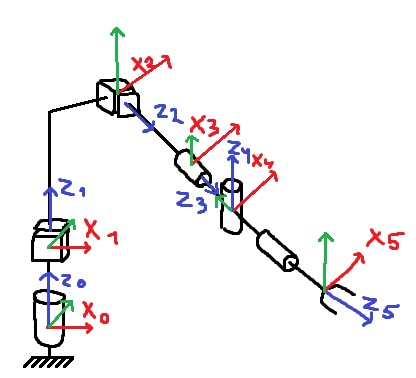

Анимации

In [ ]:
from IPython.display import HTML, Video
from matplotlib.animation import FuncAnimation
import matplotlib
from tqdm.notebook import tqdm

def generateanimation(bot, q_records, step=5, cmap='magma', path='/content/robotanim.mp4', additional_text=""):
    fig = plt.figure(figsize=(10.8, 10.8), facecolor='#1a1a1a')
    ax = fig.add_subplot(111, projection='3d')
    ax.set_facecolor('#1a1a1a')

    frames = len(q_records) // step
    progress = tqdm(total=frames, desc="Генерация анимации")
    tool_trail = []

    colormap = plt.get_cmap(cmap)
    n_body_segments = 4
    segment_colors = [colormap(0.3 + 0.5 * i / (n_body_segments - 1))
                      for i in range(n_body_segments)]

    def update(frame):
        ax.cla()
        ax.set_facecolor('#1a1a1a')
        q = q_records[frame * step]

        T01   = RMath.dh_matrix(q[0], bot.d0 + bot.d1, 0, 0)
        T12_1 = T01   @ RMath.dh_matrix(0, q[1], 0, 0)
        T12_2 = T12_1 @ RMath.dh_matrix(0, 0, bot.a2, np.pi/2)
        T23   = T12_2 @ RMath.dh_matrix(0, q[2], 0, 0)
        T34   = T23   @ RMath.dh_matrix(q[3], 0, 0, -np.pi/2)
        T45   = T34   @ RMath.dh_matrix(q[4], 0, 0,  np.pi/2)
        T56   = T45   @ RMath.dh_matrix(q[5], bot.d_G, 0, 0)

        p = [np.array([0,0,0]),T01[:3,3],T12_1[:3,3],T12_2[:3,3],T23[:3,3],T34[:3,3],T45[:3,3],T56[:3,3]]

        tool_trail.append(p[-1].copy())
        if len(tool_trail) > 1:
            trail = np.array(tool_trail)
            for i in range(len(trail) - 1):
                if i % 2 == 0:
                    ax.plot(trail[i:i+2, 0], trail[i:i+2, 1], trail[i:i+2, 2],'-', lw=1, color='#FFFFFF', alpha=1)

        body_segments = [(p[0], p[1]), (p[1], p[2]), (p[2], p[3]), (p[3], p[4])]
        for seg, color in zip(body_segments, segment_colors):
            pts = np.array(seg)
            ax.plot(pts[:,0],pts[:,1],pts[:,2],'-',lw=8,color=color,solid_capstyle='round',solid_joinstyle='round')

        tool = np.array(p[6:])
        ax.plot(tool[:,0], tool[:,1], tool[:,2],'-', lw=6, color='#444444',solid_capstyle='round', solid_joinstyle='round')

        scale = 0.3
        ax.quiver(*p[-1], *T56[:3,0], length=scale, color='#ef5350', lw=2, arrow_length_ratio=0.25)
        ax.quiver(*p[-1], *T56[:3,1], length=scale, color='#66bb6a', lw=2, arrow_length_ratio=0.25)
        ax.quiver(*p[-1], *T56[:3,2], length=scale, color='#42a5f5', lw=2, arrow_length_ratio=0.25)

        x, y, z = p[-1]
        ax.text2D(0.02, 0.95, f"Позиция инструмента: ({x:.3f}, {y:.3f}, {z:.3f})",transform=ax.transAxes, color='white',fontsize=9)
        ax.text2D(0.02, 0.98, additional_text,transform=ax.transAxes, color='white',fontsize=9)

        ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_zlim(0, 3)
        ax.set_xlabel('X', color='#666'); ax.set_ylabel('Y', color='#666')
        ax.set_zlabel('Z', color='#666')
        ax.tick_params(colors='#444')
        for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
            pane.fill = False
            pane.set_edgecolor('#2a2a2a')
        ax.grid(True, color='#2a2a2a', linewidth=0.5)
        ax.set_title(f"{frame * step} / {len(q_records)}",
                     color='#aaaaaa', fontsize=10)
        progress.update(1)

    anim = FuncAnimation(fig, update, frames=frames, interval=50)
    plt.close()

    writer = matplotlib.animation.FFMpegWriter(fps=120)
    anim.save(path, writer=writer, dpi=200)
    progress.close()

    return Video(path, embed=True, width=800)

Анимация движения по полиномиальному закону

In [ ]:
q_only = [traj[1] for traj in poly_trajectories]
q_records = np.array(q_only).T
generateanimation(manipulator, q_records, step=3, cmap='inferno', path='/content/polytrajectory.mp4', additional_text="Движение по полиномиальному закону")

Генерация анимации:   0%|          | 0/200 [00:00<?, ?it/s]

In [ ]:
q_only = [traj[1] for traj in trapezoidal_trajectories]
q_records = np.array(q_only).T
generateanimation(manipulator, q_records, step=3, cmap='inferno', path='/content/tapezoidaltrajectory.mp4', additional_text="Движение по трапезоидному закону")

Генерация анимации:   0%|          | 0/111 [00:00<?, ?it/s]

In [ ]:
generateanimation(manipulator, q_records_jac, step=3, cmap='inferno', path='/content/linearIDKtrajectory.mp4', additional_text="Движение по прямолинейной траектории полученной с помощью обратной дифференциальной кинематики")

Генерация анимации:   0%|          | 0/120 [00:00<?, ?it/s]

In [ ]:
generateanimation(manipulator, q_records_ik, step=3, cmap='inferno', path='/content/linearIKtrajectory.mp4', additional_text="Движение по прямолинейной траектории полученной с помощью обратной кинематики")

Генерация анимации:   0%|          | 0/117 [00:00<?, ?it/s]